# Transformer Attention and Spirituality (English)

This notebook explores how an English BERT model distributes **attention** across the tokens of a spirituality sentence.

> **Important:** Attention is a mathematical relation inside the model. It does not by itself prove that AI understands theological or spiritual meaning.

## 1. Install the required packages
Run this cell once. The first installation may take several minutes.

In [1]:
%pip install -q torch transformers matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Import the libraries

In [2]:
from transformers import AutoTokenizer, AutoModel
import torch
import matplotlib.pyplot as plt

print("Libraries are ready.")

Libraries are ready.


## 3. Load the English Transformer model
The model is downloaded the first time and normally loads faster on later runs.

In [3]:
model_name = "bert-base-uncased"
print("Loading the Transformer model...")

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name, output_attentions=True)
model.eval()

print("Model loaded successfully.")

Loading the Transformer model...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

c:\Users\손문\GitHub\qiskit-study\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\손문\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded successfully.


## 4. Enter and tokenize a spirituality sentence
You can replace the sentence in `text` with another English sentence.

In [4]:
text = "In times of difficulty, I pray to God and experience love through my community."

inputs = tokenizer(text, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Original sentence:")
print(text)
print("\nTokens:")
print(tokens)

Original sentence:
In times of difficulty, I pray to God and experience love through my community.

Tokens:
['[CLS]', 'in', 'times', 'of', 'difficulty', ',', 'i', 'pray', 'to', 'god', 'and', 'experience', 'love', 'through', 'my', 'community', '.', '[SEP]']


## 5. Process the sentence and collect attention

In [5]:
with torch.inference_mode():
    outputs = model(**inputs)

attentions = outputs.attentions
print("Number of Transformer layers:", len(attentions))
print("Last-layer attention tensor shape:", attentions[-1].shape)

Number of Transformer layers: 12
Last-layer attention tensor shape: torch.Size([1, 12, 18, 18])


## 6. Average the attention heads in the final layer
For this classroom demonstration, the multiple attention heads are averaged into one matrix.

In [6]:
last_attention = attentions[-1]
attention = last_attention[0].mean(dim=0)
attention_np = attention.detach().cpu().numpy()

print("Attention matrix shape:", attention_np.shape)

Attention matrix shape: (18, 18)


## 7. Visualize the attention map
Each row is a query token, and each column is a key token. Darker cells indicate relatively higher attention weights.

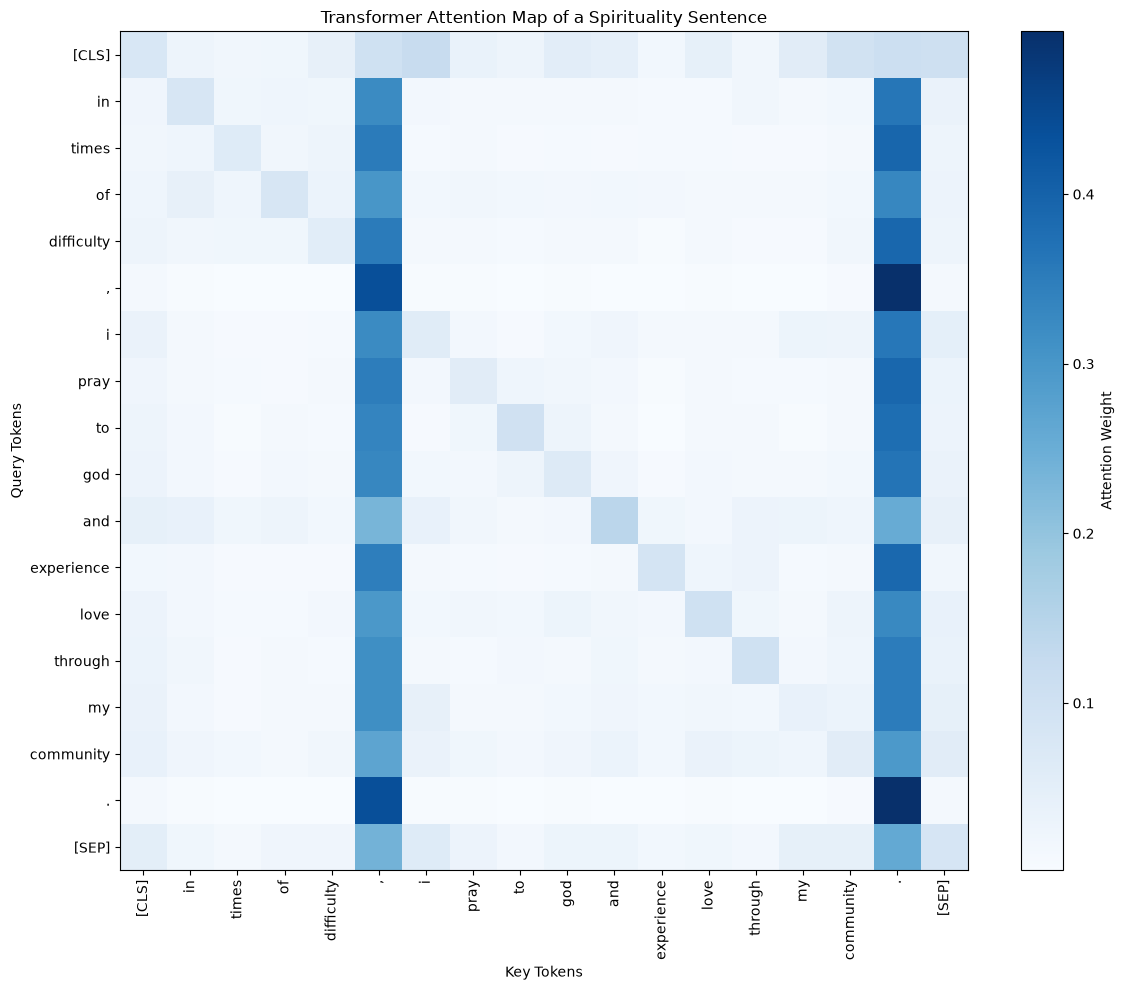

In [7]:
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(attention_np, cmap="Blues", aspect="auto")

ax.set_xticks(range(len(tokens)))
ax.set_yticks(range(len(tokens)))
ax.set_xticklabels(tokens, rotation=90)
ax.set_yticklabels(tokens)
ax.set_xlabel("Key Tokens")
ax.set_ylabel("Query Tokens")
ax.set_title("Transformer Attention Map of a Spirituality Sentence")
fig.colorbar(image, ax=ax, label="Attention Weight")

plt.tight_layout()
plt.show()

## 8. Find the strongest non-self connection for each token

In [8]:
print("Strongest attention connection for each token:\n")

for row_index, query_token in enumerate(tokens):
    scores = attention[row_index].clone()
    scores[row_index] = -1  # ignore self-attention
    key_index = int(torch.argmax(scores))
    key_token = tokens[key_index]
    score = float(scores[key_index])
    print(f"{query_token:>12}  -->  {key_token:<12} ({score:.3f})")

Strongest attention connection for each token:

       [CLS]  -->  i            (0.119)
          in  -->  .            (0.362)
       times  -->  .            (0.393)
          of  -->  .            (0.331)
  difficulty  -->  .            (0.391)
           ,  -->  .            (0.496)
           i  -->  .            (0.359)
        pray  -->  .            (0.390)
          to  -->  .            (0.377)
         god  -->  .            (0.365)
         and  -->  .            (0.254)
  experience  -->  .            (0.388)
        love  -->  .            (0.327)
     through  -->  .            (0.351)
          my  -->  .            (0.350)
   community  -->  .            (0.294)
           .  -->  ,            (0.437)
       [SEP]  -->  .            (0.259)


## 9. Religious education interpretation
Use the questions below to move from computation toward human theological interpretation.

In [9]:
print("""
============================================================
From Transformer Attention to Spiritual Interpretation
============================================================

Spiritual Experience
        -> Language
        -> Tokenization
        -> Transformer
        -> Attention
        -> Human Interpretation
        -> Spiritual Formation

Discussion Questions:
1. Which words receive strong attention from the Transformer?
2. Does the model connect 'pray' with 'God'?
3. How are 'love' and 'community' represented?
4. Does high attention mean that AI understands spiritual meaning?
5. What remains the role of human theological interpretation?
============================================================
""")


From Transformer Attention to Spiritual Interpretation

Spiritual Experience
        -> Language
        -> Tokenization
        -> Transformer
        -> Attention
        -> Human Interpretation
        -> Spiritual Formation

Discussion Questions:
1. Which words receive strong attention from the Transformer?
2. Does the model connect 'pray' with 'God'?
3. How are 'love' and 'community' represented?
4. Does high attention mean that AI understands spiritual meaning?
5. What remains the role of human theological interpretation?

